# TP 2 - Séance 1
## Filtrage fréquentiel 2D

Équipe #15
- Guindon, Théo (2255253)
- Bererd, Pierre-Louis (2552949)

In [7]:
# Importe les modules qui seront utilisés dans le laboratoire.
from typing import Optional, Tuple
import numpy as np
from scipy.ndimage import convolve
from IPython.display import clear_output
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.pyplot import imread

%matplotlib inline
# Étend la taille des figures
plt.rcParams["figure.figsize"] = (18, 8)

<font color='green'>Conseil : </font>Nous vous conseillons d'utiliser la [plateforme](https://clementpla.github.io/ComputerVisionToolbox/home) de traitement d'image présentée par Clément Playout dans le cours, particulièrement le module sur la transformée de Fourier 2D. Vous pouvez vous-même créer des signaux sinusoïdaux (en cliquant sur le bouton Draw sin(x)), changer l'angle, et visualiser le résultat de la fft 2D. 

# Exercice I : FFT de signaux théoriques 2D

On étudie le signal: $S_1(x,y)=\cos(2\pi\,(x f_x + y f_y))$ paramétré par les fréquences $f_x$ et $f_y$.

On vous fournit les fonctions ```S1(fx,fy)``` qui calcule le signal avec un échantillonage $F_e=100 px/mm$, et ```plot_fft2(fft_signal)``` qui prend en paramètre une transformée de Fourier et affiche le spectre associé.

In [ ]:
def plot_fft2(
    fft_signal: np.ndarray,
    Fe: Optional[float] = None,
    grid: bool = True,
    logscale: bool = False,
    ax: Optional[matplotlib.axes.Axes] = None,
) -> None:
    """Trace le spectre d'un signal à partir de sa transformée de Fourier.

    Args:
        fft_signal (np.ndarray): Transformée de Fourier du signal à afficher (array 2D complexe).
        Fe (float, optionnel): Fréquence d'échantillonage du signal. La valeur par défaut est None.
        grid (bool, optionnel): Si vrai, affiche une grille sur le spectre. La valeur par défaut est True.
        logscale (bool, optionnel): Si vrai, les intensités du spectre sont affichées en échelle logarithmique. La
            valeur par défaut est False
        ax : Si fourni, le spectre sera tracé dans ce subplot. La valeur par défaut est None.
    """
    # Si aucun système d'axes est fourni on en créé un.
    if ax is None:
        fig, ax = plt.subplots()

    # On calcule les bornes des abscisses et des ordonnées à partir de Fe.
    H, W = fft_signal.shape
    if Fe is not None:
        ymax = (H - (0 if H % 2 else 1)) / (2 * H) * Fe
        xmax = (W - (0 if W % 2 else 1)) / (2 * W) * Fe
        extent = (-Fe / 2, xmax, ymax, -Fe / 2)
    else:
        extent = (-W // 2, W // 2 + (W % 2), H // 2, -H // 2 - (H % 2))

    if grid:
        # Si grid est vrai, on affiche la grille
        ax.grid(color="#bbb", linestyle="dotted")
        unit = " (en $mm^{-1}$)" if Fe is not None else ""
        ax.set_xlabel("U" + unit)
        ax.set_ylabel("V" + unit)
    else:
        # Sinon on désactive les axes
        ax.axis("off")

    # On calcule le spectre (le module de la transformée de Fourier).
    fft_displayed = np.abs(fft_signal)

    if not logscale:
        # Si logscale est faux on affiche le spectre avec une colorbar
        graph = ax.imshow(fft_displayed, cmap="inferno", extent=extent)
        plt.colorbar(graph, ax=ax, fraction=0.0467, pad=0.02)
    else:
        # Sinon on nivelle les intensités trop élevées (0.1% des intensités les plus fortes)
        fft_displayed = np.clip(fft_displayed, 0, np.percentile(fft_displayed, 99.9))
        # et on affiche le spectre en intensités logarithmiques
        fft_displayed = np.log(1 + fft_displayed)
        graph = ax.imshow(fft_displayed, cmap="inferno", extent=extent, vmin=0)


def S1(fx: float, fy: float) -> np.ndarray:
    """Génère le signal S1 sur [-1, 1] x [-1, 1] avec une fréquence d'échantillonnage de 100 px/mm.

    Args:
        fx (float): Fréquence du signal en x.
        fy (float): Fréquence du signal en y.

    Returns:
        np.ndarray: Le signal S1.
    """
    y = np.arange(-1, 1, 1 / 100)
    x = np.arange(-1, 1, 1 / 100)
    # On définit une grille de coordonnées x et y
    x, y = np.meshgrid(x, y)

    # On calcule le signal pour chaque point de cette grille, c'est-à-dire pour chaque pixel de l'image.
    return np.cos(2 * np.pi * (x * fx + y * fy))

**1a.** Implémentez la fonction `compute_fft2(signal)` qui prend en argument une image et calcule sa transformée de Fourier (normalisée et avec son origine centrée).  

**1b.** En prenant $f_x = 13 \text{ mm}^{-1}$ et $f_y=0$. Affichez le signal $S_1(x,y)$ et son spectre à l'aide de `plot_fft2()`. Vérifier la position des pics et leur amplitude (donnée par la colorbar). Les valeurs des positions et d'amplitude sont-elles celles attendues ?

_(Pour gagner du temps dans la suite de l'exercice, on conseille d'encapsuler le code d'affichage d'un signal et de son spectre dans une fonction.)_

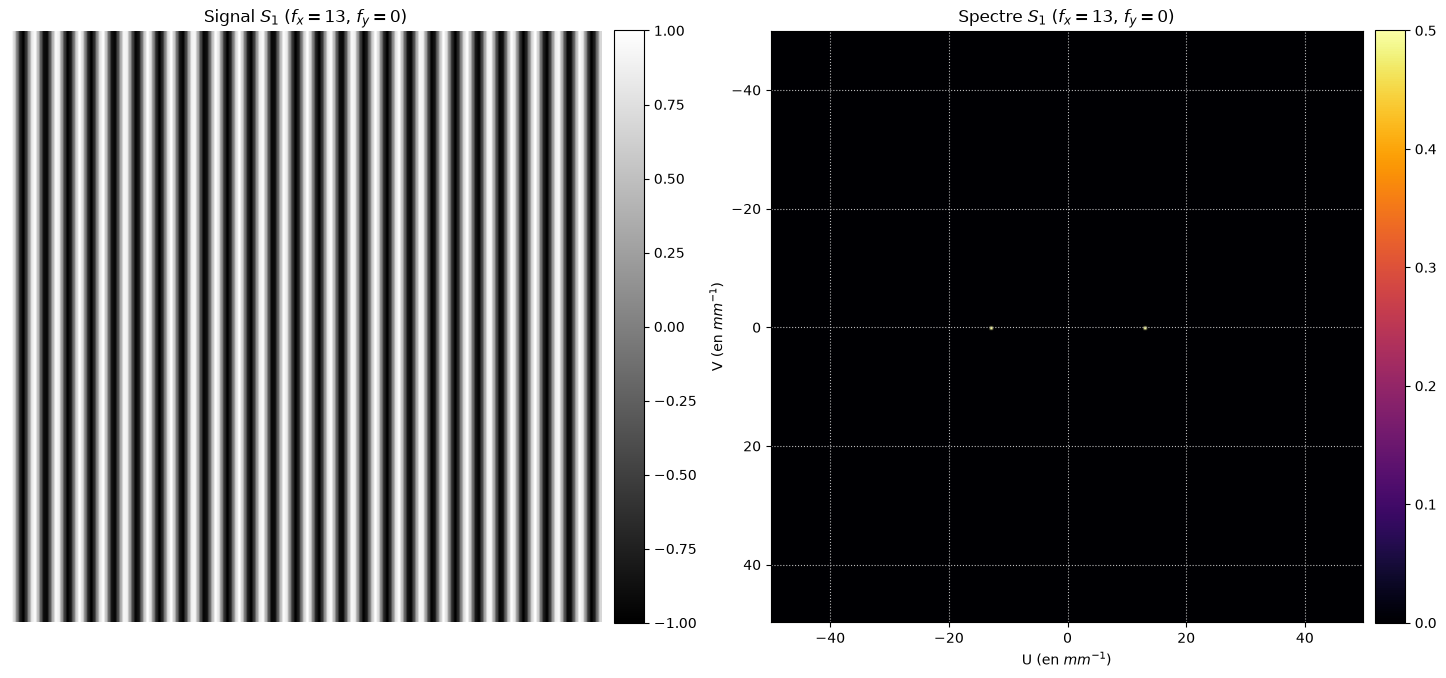

Pic en (U, V) = (-13.0, 0.0) mm^-1, amplitude = 0.500
Pic en (U, V) = (13.0, 0.0) mm^-1, amplitude = 0.500


In [9]:
def compute_fft2(signal: np.ndarray) -> np.ndarray:
    # La transformée de Fourier d'une image est calculée par np.fft.fft2(img). 
    # Comme np.fft.fft() la transformée de Fourier est renvoyé entre 0<=f<Fe,
    # utilisez np.fft.fftshift pour la centrer (fréquence entre -Fe/2<=f<Fe/2).
    # On normalise par le nombre de pixels pour que l'amplitude soit indépendante de la taille de l'image.
    return np.fft.fftshift(np.fft.fft2(signal)) / signal.size


def plot_signal_et_fft(
    signal: np.ndarray,
    Fe: Optional[float] = 100,
    titre: str = "",
    logscale: bool = False,
) -> None:
    """Affiche côte à côte un signal 2D et son spectre."""
    fig, (ax1, ax2) = plt.subplots(1, 2)
    graph = ax1.imshow(signal, cmap="gray")
    plt.colorbar(graph, ax=ax1, fraction=0.0467, pad=0.02)
    ax1.set_title(f"Signal {titre}")
    ax1.axis("off")
    plot_fft2(compute_fft2(signal), Fe=Fe, logscale=logscale, ax=ax2)
    ax2.set_title(f"Spectre {titre}")
    plt.show()


# 1b.
signal = S1(fx=13, fy=0)
plot_signal_et_fft(signal, titre="$S_1$ ($f_x=13$, $f_y=0$)")

# Vérification numérique de la position et de l'amplitude des pics
fft_s = compute_fft2(signal)
H, W = fft_s.shape
v_idx, u_idx = np.where(np.abs(fft_s) > 0.1)
freqs = np.fft.fftshift(np.fft.fftfreq(W, d=1 / 100))  # axe des fréquences en mm^-1
for v, u in zip(v_idx, u_idx):
    print(f"Pic en (U, V) = ({freqs[u]:.1f}, {freqs[v]:.1f}) mm^-1, amplitude = {np.abs(fft_s[v, u]):.3f}")

**Réponse 1b.**

S1 = cos(2π·13·x), c’est une onde plane qui varie juste selon x, donc des bandes verticales.

cos(2π fx x) = 1/2 (e^(i2π fx x) + e^(-i2π fx x)), donc la TF c’est 1/2 [δ(u-13, v) + δ(u+13, v)].

Sur le spectre on voit 2 pics symétriques par rapport à l’origine en (U,V) = (±13, 0) mm^-1, d’amplitude 0.5 (lu sur la colorbar). Donc ça correspond bien à ce qu’on attendait.

13 mm^-1 < Fe/2 = 50 mm^-1 donc pas de repliement. Résolution en fréquence = Fe/N = 100/200 = 0.5 mm^-1, donc 13 tombe pile sur un échantillon de la FFT, c’est pour ça que les pics sont ponctuels, il n'y a pas de fuite spectrale. Et comme la FFT est normalisée par le nb de pixels, l’amplitude dépend pas de la taille de l’image.

**2a.** Affichez $S_1$ et son spectre pour $f_x=0$, $f_y=13 \text{ px}^{-1}$ puis pour $f_x=5 \text{ px}^{-1}$, $f_y=12 \text{ px}^{-1}$.   

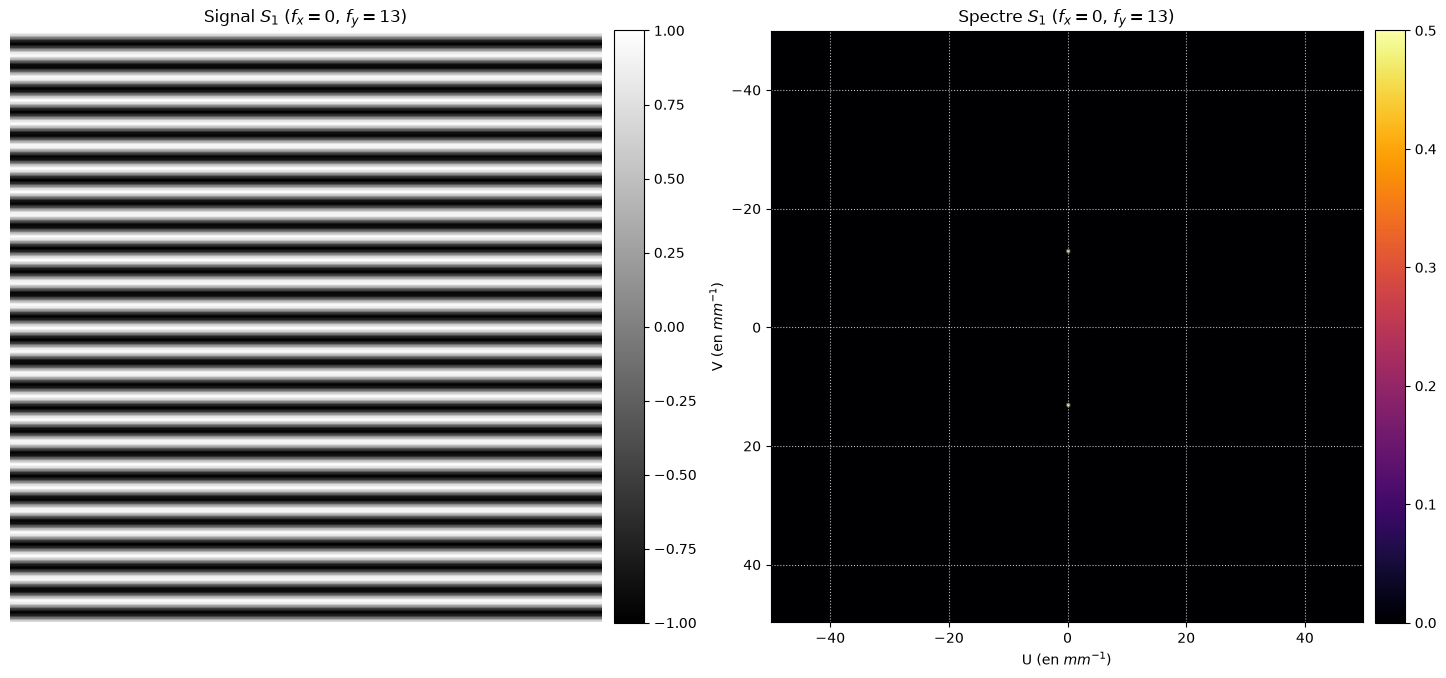

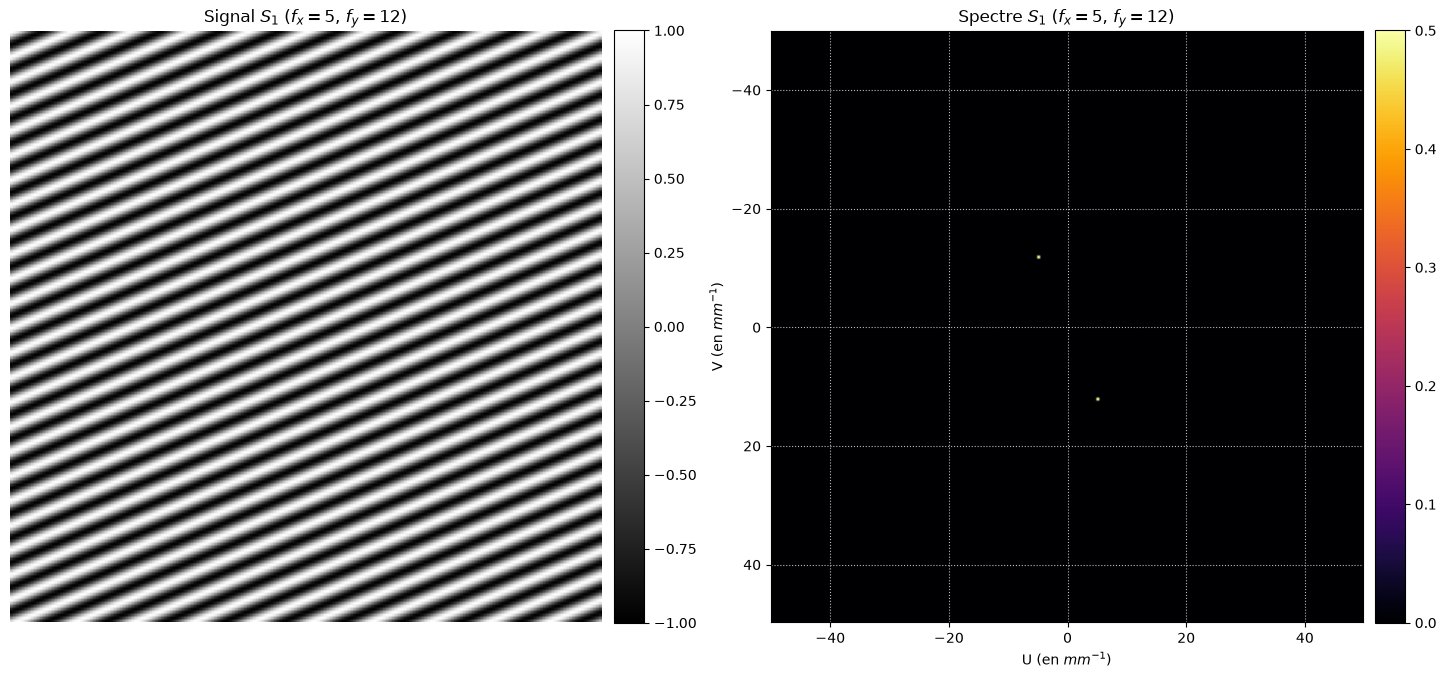

In [10]:
# 2a. (les fréquences sont en mm^-1, puisque S1 est échantillonné à Fe = 100 px/mm)
plot_signal_et_fft(S1(fx=0, fy=13), titre="$S_1$ ($f_x=0$, $f_y=13$)")
plot_signal_et_fft(S1(fx=5, fy=12), titre="$S_1$ ($f_x=5$, $f_y=12$)")

**Observations 2a.**

fx=0, fy=13 : le signal a des bandes horizontales (il varie juste selon y). Le spectre a 2 pics d’amplitude 0.5 en (U,V) = (0, ±13) mm^-1, c’est le même cas que la 1b mais tourné de 90 degrés.

fx=5, fy=12 : les bandes sont obliques, perpendiculaires au vecteur (fx, fy). Le spectre a 2 pics d’amplitude 0.5 en ±(5, 12) mm^-1. La fréquence radiale c’est racine(5ˆ2 + 12ˆ2) = 13 mm^-1, donc les pics sont à la même distance de l’origine qu’avant, mais dans une autre direction : angle = arctan(12/5) ≈ 67.4 degrés par rapport à l’axe U.

**2b.** Quel est l'effet d'une rotation de l'image sur son spectre?

**Réponse 2b.** 

Si on tourne l’image d’un angle θ, le spectre tourne du même angle θ (autour de l’origine). Les amplitudes changent pas et la distance des pics à l’origine non plus, donc la fréquence radiale est conservée.

Preuve : on pose g(x) = f(R_θ^-1 x), avec R_θ une matrice de rotation (orthogonale, det R_θ = 1). Avec un changement de variable x’ = R_θ^-1 x (le jacobien vaut 1) :

G(u) = ∬ f(R_θ^-1 x) e^(-i2π u·x) dx = ∬ f(x’) e^(-i2π (R_θ^-1 u)·x’) dx’ = F(R_θ^-1 u)

C’est ce qu’on voit en 2a : les bandes de S1 tournent et les pics du spectre tournent pareil, en restant sur le cercle de rayon 13 mm^-1 (ils sont toujours dans la direction perpendiculaire aux bandes du signal).

La prochaine question étudie le signal: $S_2(x,y) = cos(2\pi f r)$ où $r=\sqrt{x^2+y^2}$.

**3a.** En vous inspirant de l'implémentation de ```S1(fx,fy)```, définissez ```S2(f)``` (pour mieux comprendre voir la doc de [np.meshgrid](https://numpy.org/doc/stable/reference/generated/numpy.meshgrid.html)).  
Affichez le signal et son spectre pour $f=20$ et pour $f=40$.   

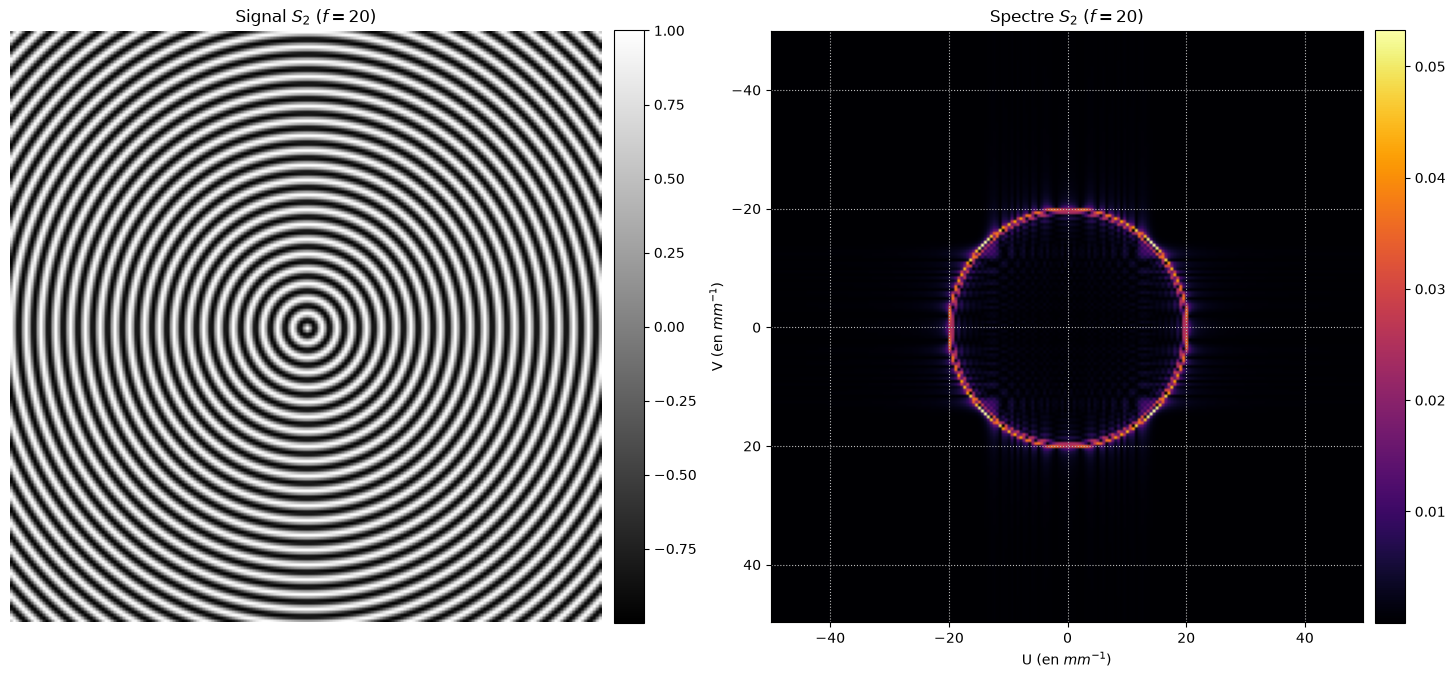

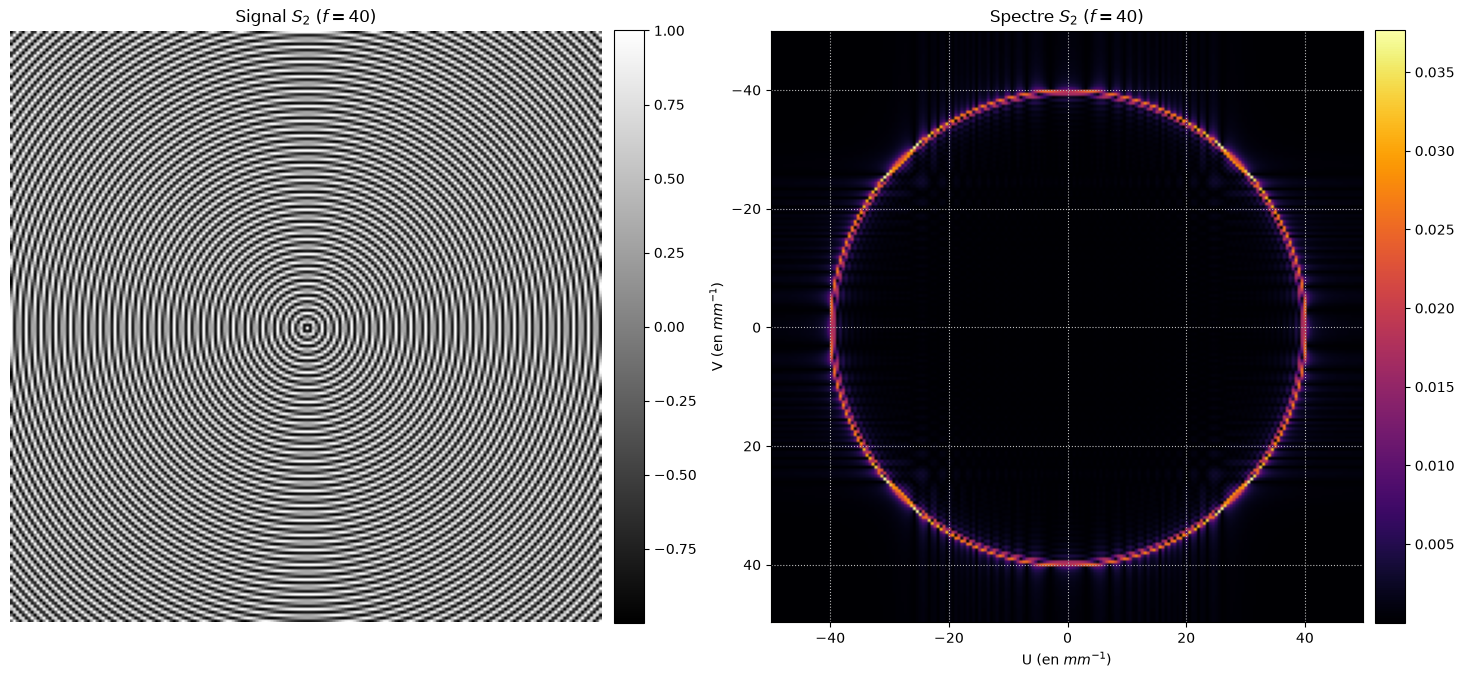

In [11]:
def S2(f: float) -> np.ndarray:
    """Génère le signal S2 = cos(2*pi*f*r) sur [-1, 1] x [-1, 1] avec une fréquence d'échantillonnage de 100 px/mm.

    Args:
        f (float): Fréquence radiale du signal (en mm^-1).

    Returns:
        np.ndarray: Le signal S2.
    """
    y = np.arange(-1, 1, 1 / 100)
    x = np.arange(-1, 1, 1 / 100)

    # Définir une grille de coordonnées x et y.
    x, y = np.meshgrid(x, y)
    # Distance de chaque pixel à l'origine.
    r = np.sqrt(x**2 + y**2)
    return np.cos(2 * np.pi * f * r)


# 3a.
plot_signal_et_fft(S2(20), titre="$S_2$ ($f=20$)")
plot_signal_et_fft(S2(40), titre="$S_2$ ($f=40$)")

**Observations 3a.**

S2 c'est des anneaux concentriques centrés sur l'origine (le signal dépend juste de r). Localement ça ressemble à une onde plane de fréquence f dans la direction radiale, donc toutes les directions sont présentes.

Alors le spectre est un cercle centré sur l'origine de rayon f : rayon 20 mm^-1 pour f=20 et rayon 40 mm^-1 pour f=40. L'énergie est répartie sur tout le cercle, donc l'amplitude en chaque point est beaucoup plus faible que les pics de 0.5 de S1. Le cercle est aussi un peu étalé (pas parfaitement fin) parce que le signal est tronqué sur [-1,1]ˆ2 et que r est pas exactement aligné sur la grille.

**3b.** Quel est l'effet d'un rétrécissement de l'image sur son spectre? 

**Réponse 3b.**

Rétrécir l'image (la compresser spatialement) ça étale son spectre, c'est l'inverse.

Théorème de similitude : si g(x,y) = f(ax, ay) avec a > 1 (rétrécissement d'un facteur a), alors

G(u,v) = 1/aˆ2 · F(u/a, v/a)

Donc le spectre est dilaté d'un facteur a (les fréquences sont multipliées par a) et son amplitude est divisée par aˆ2.

On le voit en 3a : passer de f=20 à f=40 revient à rétrécir les anneaux d'un facteur 2 (S2 avec f=40 en (x,y) = S2 avec f=20 en (2x,2y)), et le cercle du spectre passe d'un rayon 20 à un rayon 40 mm^-1. Les motifs plus petits = des fréquences plus hautes.

**3c.** Affichez le signal et le spectre pour $f=120$. Expliquez l'allure du spectre et les aberrations visibles sur le signal.

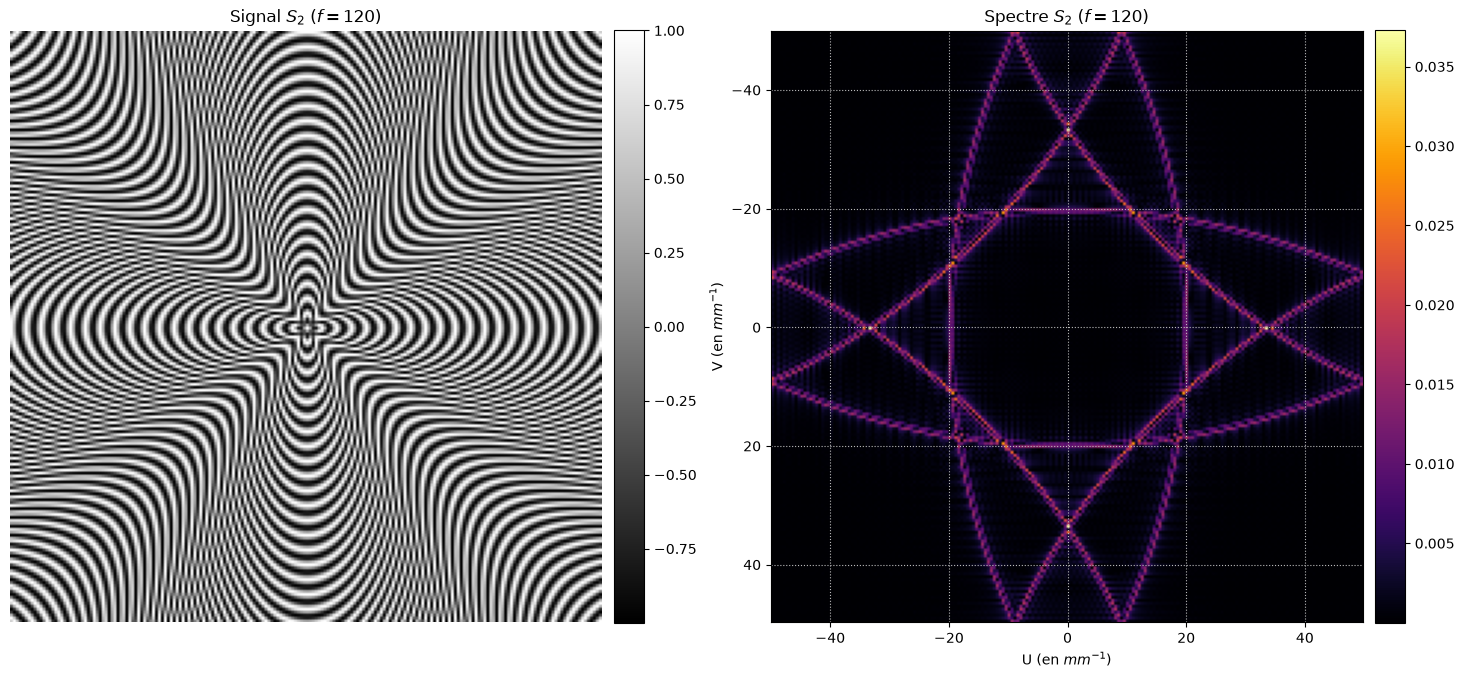

In [12]:
# 3c.
plot_signal_et_fft(S2(120), titre="$S_2$ ($f=120$)")

**Réponse 3c.**

Ici f = 120 mm^-1 > Fe/2 = 50 mm^-1, donc le critère de Shannon-Nyquist est pas respecté : il y a du repliement spectral (aliasing).

Spectre : le cercle de rayon 120 est en dehors de la fenêtre [-50, 50]ˆ2. Comme le spectre d'un signal échantillonné est périodique de période Fe = 100 dans les deux directions, ce qu'on voit c'est les morceaux des cercles de rayon 120 centrés en (±100, 0), (0, ±100), (±100, ±100) etc. qui retombent dans la fenêtre. Par exexmple, le cercle centré en (100, 0) coupe l'axe U en u = 100 - 120 = -20, et celui centré en (100,100) passe à environ 141 - 120 ≈ 21 mm^-1 de l'origine sur la diagonale. Donc on obtient un ensemble d'arcs autour de 20 mm^-1 environ, qui forment une figure qui n'est pas un vrai cercle.

Signal : à cause du repliement, la fréquence 120 est vue comme une fréquence apparente beaucoup plus basse (environ |120 - 100| = 20 mm^-1). Les anneaux sont donc beaucoup plus larges que ce qu'ils devraient être (on dirait presque S2 avec f≈20), et en plus ils sont déformés : on voit des motifs de moiré, des faux anneaux / motifs qui apparaissent ailleurs qu'au centre, et la figure n'est plus parfaitement à symétrie de révolution (elle suit la grille carrée d'échantillonnage). Ces motifs n'existent pas dans le vrai signal continu, ce sont des artefacts de sous-échantillonnage.

____

# Exercice II : Filtrage spectral

Cet exercice étudie une image angiographique du réseau coronaire: c'est-à-dire une radiographie des artères qui alimentent le coeur dans lesquelles est injecté un agent de contraste.

Tout d'abord, on souhaite définir une fonction de création de gaussienne.    
On rappelle la formule de la gaussienne en 2D d'écart-type $\sigma$ et de centre $(x_0, y_0)$: $G(x,y) = \exp\left(\dfrac{-r^2}{2 \sigma^2}\right)$ avec $r=\sqrt{(x-x_0)^2+(y-y_0)^2}$.

**1a.** Implémentez la fonction `gaussian(std, size, x0=0, y0=0)` qui renvoie une matrice de taille `size` contenant les valeurs d'une gaussienne d'écart-type `std` et centrée sur (`x0`, `y0`) avec le point central comme origine: (0,0).

**1b.** Calculez une gaussienne centrée, d'écart-type 7 dans une matrice 300x300. Affichez son image et son spectre.

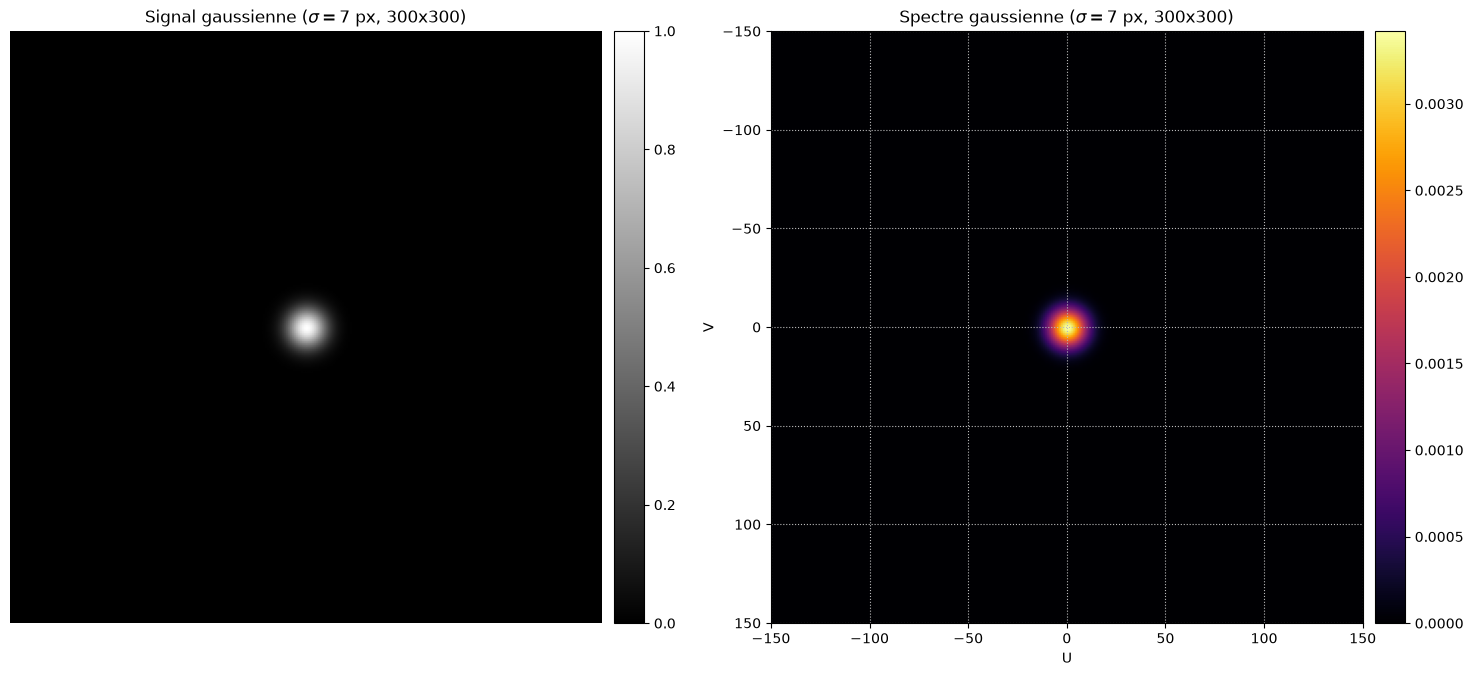

Écart-type théorique du spectre : 6.82 px (indices de fréquence)
Amplitude au centre du spectre : 0.00342 (théorie : 2*pi*7^2/300^2 = 0.00342)


In [ ]:
def gaussian(std: float, size: int, x0: float = 0, y0: float = 0) -> np.ndarray:
    """Génère une matrice carrée qui contient une gaussienne centrée en (x0, y0) avec un écart-type de std.

    Args:
        std (float): écart-type de la gaussienne.
        size (int): taille de la matrice carrée.
        x0 (float, optional): coordonnée x du centre de la gaussienne. La valeur par défaut est 0.
        y0 (float, optional): coordonnée y du centre de la gaussienne. La valeur par défaut est 0.

    Returns:
        np.ndarray: La gaussienne.
    """
    # Coordonnées des pixels avec le point central (indice size//2) comme origine,
    # ce qui correspond au centre du spectre après np.fft.fftshift.
    coords = np.arange(size) - size // 2
    x, y = np.meshgrid(coords, coords)
    r2 = (x - x0) ** 2 + (y - y0) ** 2
    return np.exp(-r2 / (2 * std**2))


# 1b. (Fe=None : les axes du spectre sont en indices de fréquence, en "pixels" du spectre)
g7 = gaussian(std=7, size=300)
plot_signal_et_fft(g7, Fe=None, titre="gaussienne ($\\sigma=7$ px, 300x300)")

# Vérification : la TF d'une gaussienne d'écart-type 7 px est une gaussienne d'écart-type 1/(2*pi*7) px^-1, 
# soit 300/(2*pi*7) ≈ 6.8 "pixels" dans le spectre 300x300.
print(f"Écart-type théorique du spectre : {300 / (2 * np.pi * 7):.2f} px (indices de fréquence)")
print(f"Amplitude au centre du spectre : {np.abs(compute_fft2(g7)).max():.5f} "
      f"(théorie : 2*pi*7^2/300^2 = {2 * np.pi * 49 / 300**2:.5f})")

**2.** Chargez l'image `angiographie_bruit.png`. Affichez l'image et son spectre.   
Identifiez sur le spectre les raies qui sont responsables des rayures diagonales sur l'angiographie (donnez les coordonnées des points concernés). 

_Pour améliorer la lisibilité du spectre, activez l'option `logscale=True`. Cette option sera laissée active dans les prochaines questions pour l'affichage de tous les spectres issus de l'image._

In [14]:
from scipy.ndimage import maximum_filter

# 2. Chargement de l'image (adapter le chemin si l'image est rangée ailleurs)
angio = imread("angiographie_bruit.png").astype(float)
if angio.ndim == 3:  # image RGB(A) -> niveaux de gris
    angio = angio[..., :3].mean(axis=2)
N = angio.shape[0]
print("Taille de l'image :", angio.shape)

T_bruit = compute_fft2(angio)
plot_signal_et_fft(angio, Fe=None, titre="angiographie bruitée", logscale=True)


def trouver_raies(T: np.ndarray, rayon_exclu: int = 10, ratio_min: float = 10) -> list:
    """Repère les pics isolés du spectre (raies) en dehors des basses fréquences.

    Un pic est retenu s'il est un maximum local et que son amplitude dépasse ratio_min fois
    l'amplitude moyenne du spectre à la même distance de l'origine (fond "naturel" de l'image).
    Renvoie la liste des coordonnées (u, v) des pics, origine au centre du spectre.
    """
    A = np.abs(T)
    H, W = A.shape
    v, u = np.mgrid[:H, :W]
    u, v = u - W // 2, v - H // 2
    r = np.round(np.sqrt(u**2 + v**2)).astype(int)
    # Profil radial moyen du spectre
    profil = np.bincount(r.ravel(), A.ravel()) / np.bincount(r.ravel())
    ratio = A / profil[r]
    est_max_local = A == maximum_filter(A, size=5)
    sel = est_max_local & (r > rayon_exclu) & (ratio > ratio_min)
    raies = [(int(u[i, j]), int(v[i, j])) for i, j in zip(*np.nonzero(sel))]
    for (uu, vv) in raies:
        print(f"Raie en (U, V) = ({uu:+d}, {vv:+d}), amplitude = {A[vv + H // 2, uu + W // 2]:.2e}, "
              f"rapport au fond = {ratio[vv + H // 2, uu + W // 2]:.0f}")
    return raies


raies = trouver_raies(T_bruit)
# Si la détection automatique ne convient pas, on peut entrer les coordonnées à la main :
# raies = [(u1, v1), (-u1, -v1), ...]

FileNotFoundError: [Errno 2] No such file or directory: 'angiographie_bruit.png'

**Réponse 2.**

Les rayures diagonales c'est une perturbation quasi sinusoïdale (périodique) qui se superpose à l'image. Comme on a vu à l'exercice I, une sinusoïde oblique donne dans le spectre une paire de pics ponctuels symétriques par rapport à l'origine, dans la direction perpendiculaire aux rayures.

Sur le spectre (en échelle log) on voit donc, en plus du contenu basse fréquence de l'angiographie qui est concentré au centre, des points brillants isolés en dehors des axes U et V : ce sont les raies responsables des rayures. Leurs coordonnées (U, V), en pixels du spectre avec l'origine au centre, sont affichées par `trouver_raies` juste au-dessus (elles vont par paires (u, v) et (-u, -v) car l'image est réelle, donc |T(-u,-v)| = |T(u,v)|).

**3.** À l'aide de la fonction ``gaussian(std, size, x0=0, y0=0)``, concevez un masque pour filtrer ces raies directement dans le domaine de Fourier (on pourra prendre un écart type de 3 pixels.) Appliquez le masque à la transformée de Fourier de l'image.   
Affichez le masque et le spectre filtré.

In [ ]:
# 3. Masque coupe-bande : on "creuse" une gaussienne d'écart-type 3 px autour de chaque raie.
masque_raies = np.ones((N, N))
for (u0, v0) in raies:
    masque_raies *= 1 - gaussian(std=3, size=N, x0=u0, y0=v0)

T0 = T_bruit * masque_raies  # spectre filtré = T_0

fig, (ax1, ax2) = plt.subplots(1, 2)
extent = (-N // 2, N // 2 + (N % 2), N // 2, -N // 2 - (N % 2))
graph = ax1.imshow(masque_raies, cmap="gray", extent=extent)
plt.colorbar(graph, ax=ax1, fraction=0.0467, pad=0.02)
ax1.set_title("Masque de suppression des raies")
ax1.set_xlabel("U")
ax1.set_ylabel("V")
plot_fft2(T0, logscale=True, ax=ax2)
ax2.set_title("Spectre filtré $T_0$")
plt.show()

**4.** Implémentez la fonction `compute_ifft2(fft_signal)` qui prend en argument la transformée de Fourier d'une image et renvoie l'image reconstituée par transformée de Fourier inverse. Reconstituez et affichez l'angiographie nettoyée de ses rayures diagonales.

Pour la suite de l'exercice on travaillera sur l'angiographie nettoyée ou sur son spectre. Sa transformée de Fourier sera notée $T_0$.

In [ ]:
def compute_ifft2(fft_signal: np.ndarray) -> np.ndarray:
    # Avant d'être basculée dans le domaine spatial, les fréquences de la transformée de Fourier du signal 
    # doivent être permutées avec np.fft.ifftshift pour être à nouveau comprises entre 0 <= f < Fe.
    # La transformée de Fourier inverse d'une image est calculée par np.fft.ifft2(img). 
    # compute_fft2 divise par le nombre de pixels, on remultiplie donc par ce nombre pour retrouver l'image.
    # L'image étant réelle, la partie imaginaire est nulle (aux erreurs numériques près) : on garde la partie réelle.
    return np.real(np.fft.ifft2(np.fft.ifftshift(fft_signal)) * fft_signal.size)


# 4. Reconstruction de l'angiographie nettoyée
angio_propre = compute_ifft2(T0)

fig, (ax1, ax2) = plt.subplots(1, 2)
ax1.imshow(angio, cmap="gray")
ax1.set_title("Angiographie bruitée")
ax1.axis("off")
ax2.imshow(angio_propre, cmap="gray")
ax2.set_title("Angiographie nettoyée (sans les rayures)")
ax2.axis("off")
plt.show()

On souhaite appliquer un filtre passe-bas dont la réponse fréquentielle est une gaussienne centrée sur l'origine d'écart-type 25.

**5.** Créez le masque gaussien correspondant, appliquez le à la transformée de Fourier de l'image et reconstituez la. Affichez l'image reconstituée et son spectre. 

On notera $T_{\text{LF}}$ la transformée de Fourier après ce filtrage.

In [ ]:
# 5. Filtre passe-bas gaussien (écart-type 25 px dans le spectre)
masque_pb = gaussian(std=25, size=N)
T_LF = T0 * masque_pb
angio_LF = compute_ifft2(T_LF)

plot_signal_et_fft(angio_LF, Fe=None, titre="passe-bas ($T_{LF}$)", logscale=True)

**6a.** Calculez l'intensité des fréquences qui ont été retirées du spectre à la question précédente, c'est-à-dire la transformée de Fourier $T_{\text{HF}}$ telle que $T_0 = T_{\text{LF}} + T_{\text{HF}}$.   
Affichez l'image reconstituée et son spectre. 

In [ ]:
# 6a. Fréquences retirées : T_HF = T_0 - T_LF = T_0 * (1 - masque_pb)
T_HF = T0 - T_LF
angio_HF = compute_ifft2(T_HF)

plot_signal_et_fft(angio_HF, Fe=None, titre="hautes fréquences ($T_{HF}$)", logscale=True)

# Vérification de la linéarité : image LF + image HF = image nettoyée
print("max |angio_LF + angio_HF - angio_propre| =", np.abs(angio_LF + angio_HF - angio_propre).max())

**6b.** Quel est le type de ce filtrage?

**Réponse 6b.**

C'est un filtrage passe-haut (gaussien) : T_HF = T_0 · (1 - G_25), donc le masque vaut 0 à l'origine et tend vers 1 loin du centre. On enlève les basses fréquences (le fond, les variations lentes d'intensité, la composante continue) et on garde les hautes fréquences.

Sur l'image reconstituée on voit surtout les contours des artères et les petits détails (et le bruit), le fond est autour de 0 (moyenne nulle puisque la composante continue est enlevée). C'est le complémentaire du passe-bas de la question 5.

**7.** Créez un masque gaussien centré d'écart-type 1.91 pixels, de taille 11x11 et normalisé pour que sa somme soit 1. Convoluez ce masque avec l'image nettoyée à la question 4.   
Affichez l'image filtrée et son spectre.

In [ ]:
# 7. Masque gaussien spatial 11x11, sigma = 1.91 px, normalisé (somme = 1)
h = gaussian(std=1.91, size=11)
h /= h.sum()

angio_conv = convolve(angio_propre, h)

plot_signal_et_fft(angio_conv, Fe=None, titre="convolution avec $h$ ($\\sigma=1.91$ px, 11x11)", logscale=True)

On rappelle que la transformée de Fourier d'une gaussienne d'écart-type $\sigma_0$ est un gaussienne d'écart-type $\frac{1}{2 \pi \sigma_0}$. Notons aussi que l'écart-type du masque de la question 5 en $\text{px}^{-1}$ est de $\frac{25}{300}$, c'est-à-dire l'écart-type de la gaussienne divisé par le nombre de pixel de la largeur (ou de la hauteur) du spectre.


**8a.** Démontrez mathématiquement l'équivalence entre les filtrages réalisés aux question 5 et 7.



**Réponse 8a.**

Notons N = 300 et σ_f = 25/N px^-1 l'écart-type du masque de la question 5 (en px^-1). Le masque fréquentiel s'écrit

M(u,v) = exp(-(uˆ2 + vˆ2) / (2σ_fˆ2)),   avec M(0,0) = 1.

Q5 : on calcule T_LF = T_0 · M, puis l'image I_LF = TFˆ-1{T_0 · M}.

D'après le théorème de convolution, un produit dans le domaine fréquentiel c'est une convolution dans le domaine spatial :

TFˆ-1{T_0 · M} = TFˆ-1{T_0} * TF⁻¹{M} = I_0 * m, avec m = TF⁻¹{M}.

Or la TF (inverse) d'une gaussienne est une gaussienne, d'écart-type inverse à un facteur 2π près :

m(x,y) = 2πσ_fˆ2 · exp(-(xˆ2 + yˆ2) / (2σ_sˆ2)), avec σ_s = 1 / (2πσ_f).

Application numérique : σ_s = 1 / (2π · 25/300) = 300 / (50π) ≈ 1.91 px, c'est exactement l'écart-type du masque de la question 7.

Pour l'amplitude : la somme du noyau spatial vaut la valeur du masque à la fréquence nulle, Σ m = M(0,0) = 1. C'est pour ça qu'on normalise h pour que sa somme fasse 1 (le filtre garde la valeur moyenne de l'image).

Donc filtrer par M dans le domaine de Fourier (Q5) revient à convoluer par la gaussienne normalisée h d'écart-type 1.91 px (Q7). Les deux méthodes donnent la même chose, aux petites différences près :
- h est tronqué à 11x11 (±5 px ≈ ±2.6σ_s), la partie coupée de la gaussienne est négligeable ;
- la multiplication de FFT correspond à une convolution circulaire alors que convolve() gère les bords par réflexion, donc il peut y avoir de légers écarts sur les bords de l'image.

On le vérifie numériquement dans la prochaine case.

In [ ]:
# 8a. Vérification numérique de l'équivalence Q5 <-> Q7
diff = np.abs(angio_LF - angio_conv)
bord = 6  # on ignore les bords (gestion différente des bords, circulaire vs réflexion)
print(f"Écart max (image entière) : {diff.max():.2e}")
print(f"Écart max (sans les bords) : {diff[bord:-bord, bord:-bord].max():.2e}")
print(f"Dynamique de l'image : {angio_propre.max() - angio_propre.min():.2e}")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3)
ax1.imshow(angio_LF, cmap="gray")
ax1.set_title("Q5 : filtrage fréquentiel")
ax2.imshow(angio_conv, cmap="gray")
ax2.set_title("Q7 : convolution spatiale")
graph = ax3.imshow(diff, cmap="inferno")

plt.colorbar(graph, ax=ax3, fraction=0.0467, pad=0.02)
ax3.set_title("|différence|")
for ax in (ax1, ax2, ax3):
    ax.axis("off")
plt.show()

**8b.** Avec quel masque faut-il convoluer l'image nettoyée pour réaliser un filtrage passe-haut équivalent à celui de la question 6 mais dans le domaine spatial?

**Réponse 8b.**

En Q6 le masque passe-haut est 1 - M. Par linéarité de la TF :

TF⁻¹{T_0 · (1 - M)} = I_0 * TF⁻¹{1} - I_0 * TFˆ-1{M} = I_0 * δ - I_0 * h = I_0 * (δ - h)

car la TF inverse d'une constante 1 est une impulsion de Dirac δ.

Il faut donc convoluer l'image nettoyée avec le masque **h_HP = δ - h**, c'est-à-dire l'impulsion unité 11x11 (1 au centre, 0 ailleurs) moins la gaussienne normalisée de la question 7 (σ = 1.91 px, somme = 1). Ce masque vaut 1 - h(0,0) au centre, -h ailleurs, et sa somme est nulle (ça enlève la composante continue, comme en Q6). Ça revient aussi à faire image - image lissée.

In [ ]:
# 8b. Masque passe-haut spatial : delta - h
delta = np.zeros_like(h)
delta[h.shape[0] // 2, h.shape[1] // 2] = 1
h_hp = delta - h
print(f"Somme du masque passe-haut : {h_hp.sum():.2e}")

angio_conv_HF = convolve(angio_propre, h_hp)
plot_signal_et_fft(angio_conv_HF, Fe=None, titre="convolution avec $\\delta - h$", logscale=True)

diff_hf = np.abs(angio_HF - angio_conv_HF)
print(f"Écart max avec Q6 (sans les bords) : {diff_hf[bord:-bord, bord:-bord].max():.2e}")

**Bonus**

Calculez et affichez la transformée de Fourier de l'image `cellules.png`. Cette image représente une certaine lignée cellulaire imagée au microscope. Est-ce que la méthode implémentée dans l'exercice II permettrait d'éliminer les lignes qui perturbent l'image ? En quoi le spectre de la FFT est-il différent de l'image angiographique de l'exercice II ?


In [ ]:
# Bonus (adapter le chemin si l'image est rangée ailleurs)
cellules = imread("cellules.png").astype(float)
if cellules.ndim == 3:
    cellules = cellules[..., :3].mean(axis=2)
print("Taille de l'image :", cellules.shape)
plot_signal_et_fft(cellules, Fe=None, titre="cellules", logscale=True)

**Réponse Bonus.** *(à vérifier/ajuster avec le spectre obtenu)*

Dans l'angiographie, les rayures sont une sinusoïde pure (périodique, sur toute l'image), donc leur énergie est concentrée dans quelques pics périodiques du spectre. Il suffit alors de couper ces points avec de petites gaussiennes (filtre coupe-bande / notch) et on enlève presque rien de l'image utile.

Pour l'image des cellules, les lignes parasites ne sont pas une sinusoïde, ce sont des lignes droites fines (non périodiques ou irrégulières). Une ligne droite dans l'image donne une ligne dans le spectre (perpendiculaire à la ligne de l'image), donc l'énergie du défaut est étalée sur toute une raie qui passe par l'origine, et pas sur quelques points isolés.

La méthode de l'exercice II ne marche donc pas telle quelle : quelques gaussiennes ponctuelles n'enlèveraient qu'une petite partie de l'énergie des lignes. Il faudrait un masque qui coupe toute la bande le long de cette raie (en gardant le voisinage de l'origine), mais ça enlève aussi le contenu des cellules qui est dans ces fréquences, donc ça peut créer des artefacts. Une méthode dans le domaine spatial (par ex. filtre médian ou correction ligne par ligne) peut être plus adaptée.